Homework no. 9 - Tymoteusz Bultrowicz - tb469198

I've decided to do exercise 5 - added extra hidden layer to neural network implemented below.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: X=(60000, 28, 28), y=(60000,)
Test: X=(10000, 28, 28), y=(10000,)


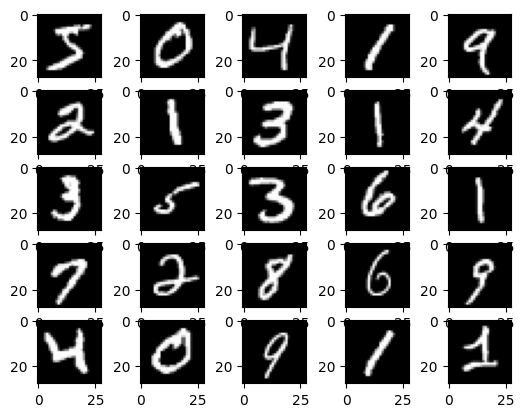

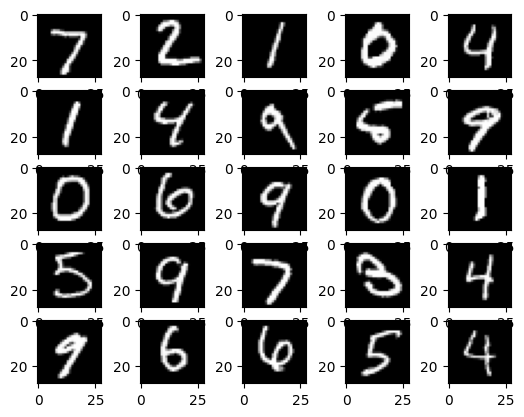

In [1]:
# example of loading and plotting the mnist dataset
from tensorflow.keras.datasets.mnist import load_data
from matplotlib import pyplot
# load dataset
(trainX, trainy), (testX, testy) = load_data()
# summarize loaded dataset
print('Train: X=%s, y=%s' % (trainX.shape, trainy.shape))
print('Test: X=%s, y=%s' % (testX.shape, testy.shape))
# plot first few images
for i in range(25):
	# define subplot
	pyplot.subplot(5, 5, i+1)
	# plot raw pixel data
	pyplot.imshow(trainX[i], cmap=pyplot.get_cmap('gray'))
# show the figure
pyplot.show()

for i in range(25):
	# define subplot
	pyplot.subplot(5, 5, i+1)
	# plot raw pixel data
	pyplot.imshow(testX[i], cmap=pyplot.get_cmap('gray'))
# show the figure
pyplot.show()

Our first goal is to build a binary classifier - we'll discern between digits 0-4 and the rest.  We'll use all the pixels in an image as the input.

First we ``flatten'' $X$ for each observation, so that it's represented by a vector rather than a 2-dimensional array. Hence the whole dataset is represented as a 2- rather than a 3-dimensional array.

For our vectorized implementation it'll be more convenient to represent X as an $k * m$ dimensional matrix, where $k$ is the number of parameters and $m$ is the number of objects (notice it's the transpose of what we're used to).


In [2]:
import numpy as np
trX = trainX.reshape([trainX.shape[0], -1])
trX = np.transpose(trX)
trY = 1*(trainy <5)
trY = trY.reshape([trY.shape[0], 1])
trY = np.transpose(trY)

teX = testX.reshape([testX.shape[0], -1])
teX = np.transpose(teX)
teY = 1*(testy < 5)
teY = teY.reshape([teY.shape[0], 1])
teY = np.transpose(teY)

In [10]:
print((trY[0]))

[0 1 1 ... 0 0 0]
(784, 60000)
(1, 60000)
(784, 10000)
(1, 10000)


We'll use a model with one hidden layer with 10 neurons and a tanh activation function. The output layer consists of a single neuron with a sigmoid activation function. We define the loss in our model as
$$L(\hat{y}, y) = -y log(\hat{y}) - (1-y) log(1-\hat{y})$$
(that's the same negative log-likelihood as in logistic regression)

The neural network that we build in code below has one hidden layer (with weights W1, b1), Z1 is the linear output, activation function for this layer is tanh, A1 is the activation vector of that layer.
Layer 2 consists of a single neuron with sigmoid activation function. The weights are W2, b2, linear output is Z2 and A2 is the network output.

In code that follows dVAR is the derivative of the cost function w.r.t. VAR.

Notice that we skip calculating the gradient of the loss w.r.t. to A2 and calculate it directly for Z2 (i.e. there's no dA2 in the code, only dZ2).



**Excercise 1:** Verify (derive) the gradient of the loss function w.r.t. to Z2.

Pick either of the following excercises:

**Excercise 2:** Implement mini-batch training, i.e. forward- and back-propagate only a subset of data (e.g. 128 training objects at a time) during a single gradient update. Repeat this over all minibatches within each iteration. (Shuffle the dataset at the beginning of each iteration).

**Excercise 3*:** rework the code to work with a multi-label classification. Denote by $y=(y_1,...,y_K)$ the one-hot encoding of $y$. Assume that $\widehat{y} = softmax(z)$ (https://en.wikipedia.org/wiki/Softmax_function). Use the following loss function: $$L(\hat{y}, y) = -\sum_{k=1}^{K} y_k log(\hat{y_k})$$
You'll need to derive the gradient of the loss function w.r.t. to Z2. It'll be analogous to the update for $L$ in current model.
Please notice that unlike neurons in the hidden layer, output from the softmax unit are coupled with eachother due to normalization.

**Excercise 4:** implement momentum optimization algorithm. https://en.wikipedia.org/wiki/Stochastic_gradient_descent#Momentum

**Excercise 5:** Add an extra hidden layer to the network (also with tanh activation) - this W2, b2, dZ2, dW2, db2 become W3, b3, dZ3, dW3, db3, whereas dW2 and db2 for new W2 and b2 are analogous to dW1 and db1 updates.

In [23]:
def initialize_parameters(n_x, n_h1, n_h2, n_y):
    """
    n_x -- size of the input layer
    n_h1 -- size of the hidden layer 1
    n_h2 -- size of the hidden layer 2
    n_y -- size of the output layer
    """

    W1 = np.random.randn(n_h1, n_x) * 0.01
    b1 = np.zeros((n_h1, 1))
    W2 = np.random.randn(n_h2, n_h1) * 0.01
    b2 = np.zeros((n_h2, 1))
    W3 = np.random.randn(n_y, n_h2) * 0.01
    b3 = np.zeros((n_y, 1))

    parameters = {"W1": W1,
                  "b1": b1,
                  "W2": W2,
                  "b2": b2,
                  "W3": W3,
                  "b3" : b3}

    return parameters

def sigmoid(x):
    return(1/(1+np.exp(-x)))

def forward_propagation(X, parameters):
    W1 = parameters['W1']
    b1 = parameters['b1']
    W2 = parameters['W2']
    b2 = parameters['b2']
    W3 = parameters['W3']
    b3 = parameters['b3']

    Z1 = np.dot(W1, X) + b1
    A1 = np.tanh(Z1)
    Z2 = np.dot(W2, A1) + b2
    A2 = np.tanh(Z2)
    Z3 = np.dot(W3, A2) + b3
    A3 = sigmoid(Z3)
    cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": A2, "Z3" : Z3, "A3" : A3}
    return A3, cache

def compute_cost(A3, Y):
    """
    cross-entropy cost
    """
    m = Y.shape[1]
    logprobs = np.multiply(np.log(A3), Y) + np.multiply(np.log(1-A3), 1-Y)
    cost = -1/m * np.sum(logprobs)
    cost = float(np.squeeze(cost))
    return cost

def backward_propagation(parameters, cache, X, Y):
    m = X.shape[1]
    W1 = parameters['W1']
    W2 = parameters['W2']
    W3 = parameters['W3']
    A1 = cache['A1']
    A2 = cache['A2']
    A3 = cache['A3']
    dZ3 = A3 - Y
    dW3 = 1/m * np.dot(dZ3, A2.T)
    db3 = 1/m * np.sum(dZ3, axis=1, keepdims=True)

    dZ2 = np.dot(W3.T, dZ3) * (1-np.power(A2, 2))
    dW2 = 1/m * np.dot(dZ2, A1.T)
    db2 = 1/m * np.sum(dZ2, axis=1, keepdims=True)

    dZ1 = np.dot(W2.T, dZ2) * (1-np.power(A1, 2))
    dW1 = 1/m * np.dot(dZ1, X.T)
    db1 = 1/m * np.sum(dZ1, axis=1, keepdims=True)

    grads = {"dW1": dW1, "db1": db1, "dW2": dW2, "db2": db2, "dW3" : dW3, "db3" : db3}
    return grads

def update_parameters(parameters, grads, learning_rate = 0.1):
    W1 = parameters['W1']
    b1 = parameters['b1']
    W2 = parameters['W2']
    b2 = parameters['b2']
    W3 = parameters['W3']
    b3 = parameters['b3']

    dW1 = grads['dW1']
    db1 = grads['db1']
    dW2 = grads['dW2']
    db2 = grads['db2']
    dW3 = grads['dW3']
    db3 = grads['db3']

    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1
    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2
    W3 = W3 - learning_rate * dW3
    b3 = b3 - learning_rate * db3
    parameters = {"W1": W1, "b1": b1, "W2": W2, "b2": b2, "W3" : W3, "b3" : b3}
    return parameters

def nn_model(X, Y, n_h1, n_h2, num_iterations = 10000, print_cost=False):
    """
    Arguments:
    X -- dataset (#features, #examples)
    Y -- labels (#outputs, #examples)
    n_h1, n_h2 -- #hidden units
    num_iterations
    """
    n_x = X.shape[0]
    n_y = Y.shape[0]
    parameters = initialize_parameters(n_x, n_h1, n_h2, n_y)

    for i in range(0, num_iterations):
        A3, cache = forward_propagation(X, parameters)
        cost = compute_cost(A3, Y)
        grads = backward_propagation(parameters, cache, X, Y)
        parameters = update_parameters(parameters, grads)
        if print_cost and i % 20 == 0:
            print ("Cost after iteration %i: %f" %(i, cost))
            Yhat = 1*(A3 > 0.5)
            print('Training set accuracy: ' + str(100*(np.mean(Yhat==Y))) + '%')

    return parameters

def predict(parameters, X):
    A3, cache = forward_propagation(X, parameters)
    predictions = 1*(A3 > 0.5)
    return predictions

In [26]:
#print(trX.shape)
#print(trY.shape)
parameters = nn_model(trX, trY, n_h1 = 10, n_h2 = 5, num_iterations = 1000, print_cost=True)

Cost after iteration 0: 0.693116
Training set accuracy: 53.644999999999996%
Cost after iteration 20: 0.692812
Training set accuracy: 50.99333333333333%
Cost after iteration 40: 0.692233
Training set accuracy: 50.99333333333333%
Cost after iteration 60: 0.689444
Training set accuracy: 50.99333333333333%
Cost after iteration 80: 0.665050
Training set accuracy: 76.76166666666666%
Cost after iteration 100: 0.577262
Training set accuracy: 77.435%
Cost after iteration 120: 0.481878
Training set accuracy: 81.38499999999999%
Cost after iteration 140: 0.434382
Training set accuracy: 83.025%
Cost after iteration 160: 0.376196
Training set accuracy: 86.65%
Cost after iteration 180: 0.316808
Training set accuracy: 89.51166666666667%
Cost after iteration 200: 0.283598
Training set accuracy: 90.99000000000001%
Cost after iteration 220: 0.258135
Training set accuracy: 91.74166666666666%
Cost after iteration 240: 0.259670
Training set accuracy: 91.34666666666666%
Cost after iteration 260: 0.250989
Tra

In [27]:
ypred=predict(parameters, teX)
print('Test set accuracy: ' + str(100*(np.mean(ypred==teY))) + '%')

Test set accuracy: 95.48%


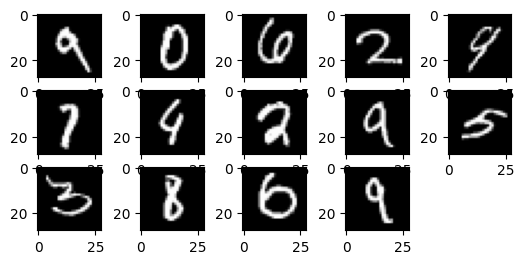

In [28]:
i=0
for j in range(300):
  if (ypred[0][j] != teY[0][j]):
    # define subplot
    pyplot.subplot(5, 5, i+1)
    i=i+1
    # plot raw pixel data
    pyplot.imshow(testX[j], cmap=pyplot.get_cmap('gray'))
# show the figure
pyplot.show()